# Fig. 3 — sensitivity of the probe–enhancer readout

> Type set for PNAS (`pnas-new`): 8 pt text, 7 pt tick labels, 10 pt panel letters as printed. Writes `fig3/fig3.pdf`. The previous layout is kept in `../alt/fig3/`.

Draws the figure from `processed_data/` and saves `fig3/fig3.pdf`.
See `figure_production/README.md` to regenerate the data.

In [1]:
import os

# This notebook reads processed_data/... relative to figure_production/, so it
# has to run there. Find that directory rather than assume the kernel started
# in it: Jupyter starts in the notebook's folder, VS Code wherever the
# workspace was opened, which may be several levels above or beside it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "README.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE

    # the notebook's own location first -- VS Code exposes it, and it is the
    # one answer that does not depend on where the kernel was started
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))

    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent

    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt

    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "README.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())


working directory: /Users/tmora/NextCloudCNRS/Code/droplet/prewet-gene/figure_production


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("processed_data")       # relative to figure_production/
OUT = Path("fig3")


# float_precision="round_trip" is not optional: pandas' default CSV float parser
# is not correctly rounded, and the LOOCV behind panel B is ill-conditioned
# enough that a one-ULP perturbation selects a different smoothing weight.
def read(name):
    return pd.read_csv(DATA / name, float_precision="round_trip")


fisher = read("fig3_fisher_input.csv")
S = json.loads((DATA / "fig3_scalars.json").read_text())

theta = S["theta"]
phi_R = S["phi_R"]
mean_toff_rnap = S["mean_toff_rnap"]

phi_inf = fisher["c_phi"].to_numpy()
phi_local_closed = fisher["phi_local_closed"].to_numpy()
phi_local_open = fisher["phi_local_open"].to_numpy()
pclosed = fisher["p_closed"].to_numpy()
popen = fisher["p_open"].to_numpy()

print("prepared {} from {}".format(S["generated_at"], S["source_data"]))
print("SPRT: eps={epsilon}, K=log((1-eps)/eps)={K:.4f}, dc/c={delta_c_over_c}"
      .format(**S))

prepared 2026-10-08T09:11:58+00:00 from data/20260423
SPRT: eps=0.32, K=log((1-eps)/eps)=0.7538, dc/c=0.1


In [3]:
def use_latex():
    # amsmath is needed for \dfrac in panel A's label; matplotlib's usetex
    # preamble does not load it, and plain LaTeX has no \dfrac.
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        fig = plt.figure()
        fig.text(0.5, 0.5, r"$\dfrac{\dot{\mathcal{F}}_{\rm local}}{P(c+\delta c)}$")
        fig.canvas.draw()
        plt.close(fig)
        return True
    except Exception as exc:
        plt.close("all")
        plt.rcParams.update({"text.usetex": False, "font.family": "sans-serif"})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


In [4]:
def _best_split(q):
    """Cheapest single sign change of q -> (cost, k, orientation)."""
    A = np.maximum(-q, 0.0) ** 2
    B = np.maximum(q, 0.0) ** 2
    cA = np.concatenate(([0.0], np.cumsum(A)))
    cB = np.concatenate(([0.0], np.cumsum(B)))
    cost_p = cA + (cB[-1] - cB)
    cost_m = cB + (cA[-1] - cA)
    kp, km = int(np.argmin(cost_p)), int(np.argmin(cost_m))
    return (cost_p[kp], kp, +1) if cost_p[kp] <= cost_m[km] else (cost_m[km], km, -1)


def fit_shape(x, d, w=None, lam=1e-5, n_sub=6, pen=1e6, n_iter=50, split=None,
              lo=0.0, hi=1.0):
    x, d = np.asarray(x, float), np.asarray(d, float)
    N = d.size
    w = np.ones(N) if w is None else np.asarray(w, float)
    xs, ys = x[-1] - x[0], np.max(np.abs(d))
    n = (N - 1) * n_sub + 1
    t = np.linspace(0.0, 1.0, n)
    h = t[1] - t[0]
    idx = np.arange(N) * n_sub
    v = d / ys
    lb, ub = lo / ys, hi / ys
    E1 = (np.eye(n, k=1) - np.eye(n))[:-1]
    E2 = (np.eye(n, k=1) * -2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S_ = np.zeros((N, n))
    S_[np.arange(N), idx] = 1.0
    A0 = S_.T @ (w[:, None] * S_) / w.sum() + lam * h * (E2.T @ E2) / h ** 4
    A0 += 1e-12 * np.trace(A0) / n * np.eye(n)
    b0 = S_.T @ (w * v) / w.sum()

    u = np.clip(np.interp(t, (x - x[0]) / xs, v), lb, ub)
    k, o, prev = E2.shape[0] // 2, +1, None
    for _ in range(n_iter):
        g, q = E1 @ u, E2 @ u
        if split is None:
            _, k, o = _best_split(q)
        else:
            k, o = split
        sgn = np.where(np.arange(q.size) < k, o, -o)
        P = (g < 0).astype(float)
        Q = (q * sgn < 0).astype(float)
        L = (u < lb).astype(float)
        U = (u > ub).astype(float)
        A = (A0 + pen * (E1.T @ (P[:, None] * E1)) + pen * (E2.T @ (Q[:, None] * E2))
             + pen * np.diag(L + U))
        b = b0 + pen * (L * lb + U * ub)
        u = np.linalg.solve(A, b)
        key = (P.tobytes(), Q.tobytes(), L.tobytes(), U.tobytes(), k, o)
        if key == prev:
            break
        prev = key

    box_viol = float(np.max(np.maximum(np.maximum(lb - u, u - ub), 0.0)) * ys)
    u = np.clip(u, lb, ub)
    xf, y = x[0] + xs * t, u * ys
    q = (E2 @ u) * ys / (xs * h) ** 2

    H = np.linalg.solve(A, S_.T * w / w.sum())
    G = np.zeros((n, n))
    dxf = xs * h
    for j in range(n):
        if j == 0:
            G[j, 0:3] = np.array([-3, 4, -1]) / (2 * dxf)
        elif j == n - 1:
            G[j, -3:] = np.array([1, -4, 3]) / (2 * dxf)
        else:
            G[j, j - 1], G[j, j + 1] = -1 / (2 * dxf), 1 / (2 * dxf)

    return dict(x=xf, y=y, dy=G @ y, d2y=q, idx=idx, bounds=(lo, hi),
                lam=lam, orientation=o, x_infl=xf[1:-1][min(k, n - 3)],
                mono_viol=min(np.min(np.diff(y)), 0.0), H=H, G=G,
                edf=float(np.trace(H[idx])), box_viol=box_viol,
                infl_viol=np.max(np.maximum(
                    -q * np.where(np.arange(q.size) < k, o, -o), 0))
                    / np.max(np.abs(q)))


def loocv_lambda(x, d, lams, **kw):
    cv, loo = [], {}
    for lam in lams:
        e = np.zeros(len(d))
        for k in range(len(d)):
            w = np.ones(len(d))
            w[k] = 0.0
            f = fit_shape(x, d, w=w, lam=lam, **kw)
            e[k] = f["y"][f["idx"][k]] - d[k]
        cv.append(np.mean(e ** 2))
        loo[lam] = e
    cv = np.array(cv)
    lam = lams[int(np.argmin(cv))]
    return lam, cv, loo[lam]


def boot_replicates(x, d, lam, e_loo, nboot=400, seed=0, **kw):
    """Wild bootstrap of the LOO residuals: sign-flip, refit."""
    rng = np.random.default_rng(seed)
    f = fit_shape(x, d, lam=lam, **kw)
    yhat = f["y"][f["idx"]]
    Y = np.empty((nboot, f["x"].size))
    D = np.empty_like(Y)
    C = np.empty(nboot)
    for b in range(nboot):
        fb = fit_shape(x, yhat + e_loo * rng.choice([-1.0, 1.0], len(d)),
                       lam=lam, **kw)
        Y[b], D[b], C[b] = fb["y"], fb["dy"], fb["x_infl"]
    return Y, D, C

In [5]:
BOX = dict(lo=1e-6, hi=1.0)       # lo>0: phi_local sits in a denominator below
lams = np.logspace(-7, -1, 13)

lam_c, cv_c, eloo_c = loocv_lambda(phi_inf, phi_local_closed, lams, **BOX)
lam_o, cv_o, eloo_o = loocv_lambda(phi_inf, phi_local_open, lams, **BOX)
fit_c = fit_shape(phi_inf, phi_local_closed, lam=lam_c, **BOX)
fit_o = fit_shape(phi_inf, phi_local_open, lam=lam_o, **BOX)

# NB the notebook fits pclosed/popen at lam_c/lam_o, not at their own LOOCV
fit_pc = fit_shape(phi_inf, pclosed, lam=lam_c, **BOX)
fit_po = fit_shape(phi_inf, popen, lam=lam_o, **BOX)

Yc, Dc, Cc = boot_replicates(phi_inf, phi_local_closed, lam_c, eloo_c, **BOX)
Yo, Do, Co = boot_replicates(phi_inf, phi_local_open, lam_o, eloo_o, **BOX)

for nm, f, e in (("closed", fit_c, eloo_c), ("open", fit_o, eloo_o)):
    print("{:6s} lam={:.1e} edf={:.1f} sigma_loo={:.4f}  c*={:.5f}".format(
        nm, f["lam"], f["edf"], np.sqrt(np.mean(e ** 2)), f["x_infl"]))

closed lam=3.2e-06 edf=6.1 sigma_loo=0.0181  c*=0.00717
open   lam=3.2e-07 edf=12.8 sigma_loo=0.0040  c*=0.01283


In [6]:
xf = fit_c["x"]

kb_bands = 1 / (phi_R * mean_toff_rnap)
ku_bands = S["K_D_bands"] * kb_bands


def fisher_rate(y, dy, kb, ku):
    return (dy * xf / y) ** 2 / (1 / (kb * y) + 1 / ku)


Fc_b = np.array([fisher_rate(Yc[b], Dc[b], kb_bands, ku_bands) for b in range(len(Yc))])
Fo_b = np.array([fisher_rate(Yo[b], Do[b], kb_bands, ku_bands) for b in range(len(Yo))])
qc, qo = (np.percentile(Z, [10, 90], axis=0) for Z in (Fc_b, Fo_b))

kb = 1 / (phi_R * mean_toff_rnap)
ku = S["K_D_curves"] * kb
popen_f, pclosed_f = fit_po["y"], fit_pc["y"]

F_open = fisher_rate(fit_o["y"], fit_o["dy"], kb, ku)
F_closed = fisher_rate(fit_c["y"], fit_c["dy"], kb, ku)
F_free = 1 / (1 / (kb * xf) + 1 / ku)
F_local = pclosed_f * F_closed + popen_f * F_open

In [7]:
# ---- the physical scale, for the record (it does not enter the drawing) ----
# Panel A's drift is fixed by panel B: V = (1/2)(dc/c)^2 * Fdot(c). Evaluated at
# the most sensitive concentration with the paper's eps = 0.32 and dc/c = 0.1,
# this reproduces the order of magnitude quoted in lattice.tex ("about 4000
# Monte Carlo samples").
i_star = int(np.nanargmax(F_local))
V_phys = 0.5 * S["delta_c_over_c"] ** 2 * float(F_local[i_star])
print("most sensitive c   = {:.1f} uM".format(xf[i_star] * theta))
print("Fdot_local         = {:.3e} bits/MCS".format(F_local[i_star]))
print("V = D              = {:.3e} /MCS".format(V_phys))
print("<T_dec> = (K/V)tanh(K/2) = {:.0f} MCS   [K = {:.4f}, eps = {}]"
      .format(S["K"] / V_phys * np.tanh(S["K"] / 2), S["K"], S["epsilon"]))

most sensitive c   = 42.7 uM
Fdot_local         = 7.287e-03 bits/MCS
V = D              = 3.644e-05 /MCS
<T_dec> = (K/V)tanh(K/2) = 7448 MCS   [K = 0.7538, eps = 0.32]


In [8]:
# ---- panel A is a cartoon, drawn in units of V ----------------------------
# Drift and diffusion are equal, so the process R(t) = V t + sqrt(2V) W(t) is
# scale free apart from K: rescaling time by K leaves a walk whose only
# parameter is K, which sets how noisy the trace looks against its thresholds.
V = 1.0
K = 3.0
SEED = 250          # a realization whose crossing lands near <T_dec>, so the
                    # picture is not of an unusually quick or slow decision

T_mean = K * np.tanh(K / 2)             # <T_dec> in these units
dt = T_mean / 4000 * 1.6
n_steps = int(6 * T_mean / dt)

rng = np.random.default_rng(SEED)
R = np.concatenate(([0.0], np.cumsum(V * dt + np.sqrt(2 * V * dt)
                                     * rng.standard_normal(n_steps))))
t_sprt = np.arange(R.size) * dt

hit = int(np.argmax(np.abs(R) >= K)) if np.any(np.abs(R) >= K) else R.size - 1
T_dec = t_sprt[hit]
keep = slice(0, min(R.size, int(hit * 1.55)))     # carry on past the decision
t_sprt, R = t_sprt[keep], R[keep]
print("cartoon: K = {:.0f}, <T_dec> = {:.2f}, this realization decides at {:.2f}"
      .format(K, T_mean, T_dec))

cartoon: K = 3, <T_dec> = 2.72, this realization decides at 2.71


figure 231.9 x 240.5 pt  =  3.222 x 3.340 in


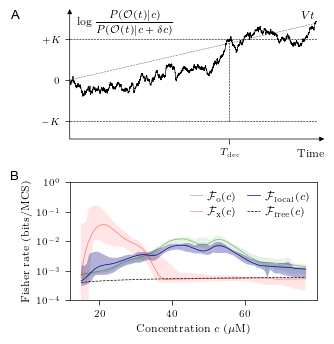

In [9]:
# ---- print geometry -------------------------------------------------------
# revtex4 twocolumn on A4: \textwidth = 481.9 pt, \columnsep = 18 pt, so a
# single-column figure is 231.95 pt wide. Building at exactly that width means
# LaTeX applies scale factor 1.
#
# The layout is explicit, in points, rather than constrained_layout: the panel
# letters each need a reserved line of their own, and a layout engine will not
# set aside space for figure-level text. Laying it out by hand also pins both
# axes to the same left edge, so the letters and the axes line up.
# PNAS (pnas-new, 9pt): \columnwidth = (505.69 - 13.5)/2 TeX pt = 245.28 bp, so a figure built
# 231.95 pt wide is printed 1.0575x larger. The geometry is in built points
# and the type is set so that the PRINTED sizes are 8 pt text,
# 7 pt tick labels and 10 pt panel letters.
PNAS_W, BUILT_W = 245.28, 231.95
PRINT = PNAS_W / BUILT_W
PT_CAPTION, PT_TICK, PT_LETTER = 8 / PRINT, 7 / PRINT, 10 / PRINT

W = 231.95                  # \columnwidth, in points
LEFT, RIGHT = 44.0, 10.0    # room for B's y-label + tick labels;
                            # RIGHT also leaves space for the
                            # arrowhead on panel A's x axis
PAD_T, PAD_B = 1.0, 2.0
LETTER_H = 15.0             # B's letter, on its own line above the panel
ARROW_A = 0.10              # A's y arrow overshoots the axes by this fraction
H_A = 85.0                  # panel A axes height; nothing above A but the
HEAD_A = ARROW_A * H_A      # y arrow, whose tip sets the top of the page
XLAB_A = 16.0               # ticks + T_dec; "Time" sits on that same line
GAP = 0.0                   # extra breathing room between the panels
H_B, XLAB_B = H_A, 28.0     # B is as tall as A

H = (PAD_T + HEAD_A + H_A + XLAB_A + GAP
     + LETTER_H + H_B + XLAB_B + PAD_B)
AXW = W - LEFT - RIGHT
LABEL_DX = 5.0              # log-ratio label: this far right of the y axis

# walk down the page, in points from the top
y_page_top = H - PAD_T
yA_top = y_page_top - HEAD_A
yA_bot = yA_top - H_A
y = yA_bot - XLAB_A - GAP
yB_letter = y - LETTER_H
yB_top, yB_bot = yB_letter, yB_letter - H_B

# Stroke weight in printed points -- the same number as in fig2 and fig4,
# so the three figures are one set. Panel A keeps its own finer weights:
# it is a schematic trace, not data.
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5   # data, guides, frame/ticks

RC = {
    "font.size": PT_CAPTION,
    "axes.labelsize": PT_CAPTION,
    "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK,
    "ytick.labelsize": PT_TICK,
    "lines.linewidth": LW,
    "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "axes.spines.top": True,
    "axes.spines.right": True,
}

COL_W, FIG_H = W / 72, H / 72
print("figure {:.1f} x {:.1f} pt  =  {:.3f} x {:.3f} in".format(W, H, COL_W, FIG_H))

with plt.rc_context(RC):
    fig3 = plt.figure(figsize=(COL_W, FIG_H))
    pA = fig3.add_axes([LEFT / W, yA_bot / H, AXW / W, H_A / H])
    pB = fig3.add_axes([LEFT / W, yB_bot / H, AXW / W, H_B / H])

    # ---- A: sequential probability ratio test -----------------------------
    pA.axhline(K, ls="dashed", color="black", lw=LW_AUX)
    pA.axhline(-K, ls="dashed", color="black", lw=LW_AUX)
    pA.plot(t_sprt, R, color="black", lw=0.5)
    pA.plot(t_sprt, V * t_sprt, ls="dashed", color="black", lw=LW_AUX, alpha=0.6)
    pA.annotate(r"$Vt$", xy=(t_sprt[-1], V * t_sprt[-1]),
                xytext=(-1, 2), textcoords="offset points",
                ha="right", va="bottom")
    pA.plot([T_dec, T_dec], [-K, K], ls="dashed", color="black", lw=LW_AUX)

    pA.set_yticks([-K, 0, K])
    pA.set_yticklabels([r"$-K$", r"$0$", r"$+K$"])
    pA.set_xticks([T_dec])
    pA.set_xticklabels([r"$T_{\rm dec}$"])
    pA.set_xlim(0, t_sprt[-1])
    pA.set_ylim(-1.45 * K, 1.45 * K)
    # "Time" right under the tip of the x arrow, on the line of the T_dec
    # tick label (same offset below the axis: tick length + pad, top-aligned)
    _drop = plt.rcParams["xtick.major.size"] + plt.rcParams["xtick.major.pad"]
    pA.annotate("Time", xy=(1.0 + 0.03, 0.0), xycoords="axes fraction",
                xytext=(0, -_drop), textcoords="offset points",
                ha="right", va="top", fontsize=PT_CAPTION,
                annotation_clip=False)

    # ---- A's axes drawn as arrows ----------------------------------------
    # the axes read as directions rather than as a measured frame. The ticks
    # (+/-K, 0, T_dec) are untouched and still sit on the axes edges.
    for _s in ("left", "bottom", "top", "right"):   # no box: arrows only
        pA.spines[_s].set_visible(False)
    _arrow = dict(arrowstyle="-|>", mutation_scale=7, color="black",
                  lw=LW_AXES, shrinkA=0, shrinkB=0)
    for _tip in ((0.0, 1.0 + ARROW_A), (1.03, 0.0)):          # up the y axis, along the x
        pA.annotate("", xy=_tip, xytext=(0.0, 0.0),
                    xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=_arrow, annotation_clip=False)
    # the log-likelihood ratio: horizontal, just right of the y arrow, its
    # top level with the arrow tip; it hangs into the empty upper left of
    # the panel, above the +K line
    fig3.text((LEFT + LABEL_DX) / W, y_page_top / H,
              r"$\log\dfrac{P(\mathcal{O}(t)|c)}{P(\mathcal{O}(t)|c+\delta c)}$",
              ha="left", va="top")

    # ---- B: local Fisher information rate ---------------------------------
    pB.fill_between(xf[3:] * theta, qc[0][3:], qc[1][3:], color="red", alpha=0.1, lw=0)
    pB.fill_between(xf[3:] * theta, qo[0][3:], qo[1][3:], color="green", alpha=0.1, lw=0)
    pB.fill_between(xf[3:] * theta,
                    pclosed_f[3:] * qc[0][3:] + popen_f[3:] * qo[0][3:],
                    pclosed_f[3:] * qc[1][3:] + popen_f[3:] * qo[1][3:],
                    color="navy", alpha=0.3, lw=0)
    pB.plot(xf[3:] * theta, F_open[3:], color="green", alpha=0.5,
            label=r"$\dot{\mathcal{F}}_{\rm o}(c)$")
    pB.plot(xf[3:] * theta, F_closed[3:], color="red", alpha=0.5,
            label=r"$\dot{\mathcal{F}}_{\rm x}(c)$")
    pB.plot(xf[3:] * theta, F_local[3:], color="navy",
            label=r"$\dot{\mathcal{F}}_{\rm local}(c)$")
    pB.plot(xf[3:] * theta, F_free[3:], ls="dashed", color="black",
            label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
    pB.set_yscale("log")
    pB.set_ylim(1e-4, 1)
    pB.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1])   # every decade, as at the
                                                 # old height (the locator
                                                 # thins them when B is short)
    pB.legend(edgecolor="none", loc="upper right", ncol=2,
              handlelength=1.2, columnspacing=1.0, handletextpad=0.5,
              borderpad=0.2, labelspacing=0.3)
    pB.set_xlabel(r"Concentration $c$  $(\mu$M)")
    pB.set_ylabel(r"Fisher rate (bits/MCS)")

    # ---- panel letters: Arial, outside LaTeX ------------------------------
    # Flush with the left edge of the figure, each on its own reserved line
    # above its panel, so nothing else sits on that line.
    # A has no line of its own: its letter is top-aligned with the page.
    fig3.text(1.0 / W, y_page_top / H, "A", usetex=False,
              fontfamily="Arial", fontsize=PT_LETTER, ha="left", va="top")
    fig3.text(1.0 / W, yB_letter / H, "B", usetex=False,
              fontfamily="Arial", fontsize=PT_LETTER, ha="left", va="bottom")

plt.show()

In [10]:
OUT.mkdir(parents=True, exist_ok=True)
path = OUT / "fig3.pdf"
# no bbox_inches="tight": the page must stay exactly \columnwidth wide
fig3.savefig(path, format="pdf")
print("Saved figure to", path)

Saved figure to fig3/fig3.pdf


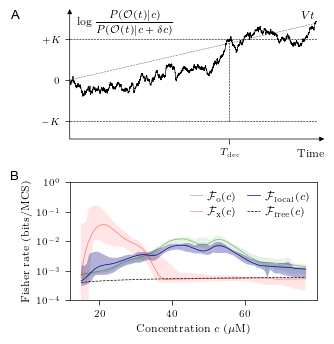

In [11]:
# The figure is created in one cell and drawn across several, so Jupyter never
# auto-displays it (the inline backend only shows figures created in the cell
# being run). Display it explicitly.
from IPython.display import display
display(fig3)